# Assignment 3: EDA on Telecom Churn Data
**Course:** DMS672 — Data Mining and Analytics

**Objective:** Analyze the nature of the attributes in the Telco Customer Churn dataset and perform basic Exploratory Data Analysis (Chapter 2 concepts) to determine which types of customers are more likely to churn. As an example, we compare the behavior of Senior Citizens (SC) vs non-SC regarding `MonthlyCharges` using a Q-Q plot.


## 1. Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import chi2_contingency

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100
%matplotlib inline


In [2]:
df = pd.read_excel("Telco-Customer-Churn.xlsx")  # update path if needed
print("Shape:", df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Nature of the Attributes

Before any analysis, we classify each attribute by its **measurement scale**, which determines what kind of statistics/plots are valid for it.

| Attribute | Type | Scale |
|---|---|---|
| `customerID` | Identifier | Nominal (unique, not analytically useful) |
| `gender` | Categorical | Nominal (binary) |
| `SeniorCitizen` | Categorical (encoded 0/1) | Nominal (binary) |
| `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn` | Categorical | Nominal (binary) |
| `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaymentMethod` | Categorical | Nominal (multi-level) |
| `tenure` | Numeric | Ratio, discrete (months) |
| `MonthlyCharges` | Numeric | Ratio, continuous |
| `TotalCharges` | Numeric | Ratio, continuous |

`Churn` (Yes/No) is our **target variable**.


In [3]:
print(df.dtypes)
print("\nUnique value counts for categorical-looking columns:")
for c in df.columns:
    if df[c].dtype == object and c not in ['customerID']:
        print(f"  {c}: {df[c].nunique()} -> {df[c].unique()[:6]}")


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges         object
Churn                   str
dtype: object

Unique value counts for categorical-looking columns:
  TotalCharges: 6531 -> [29.85 1889.5 108.15 1840.75 151.65 820.5]


## 3. Data Quality Checks & Cleaning

`TotalCharges` is stored as `object` dtype even though it's numeric — this usually means some rows contain blank strings rather than numbers. We coerce it and inspect what breaks.


In [4]:
# Check for missing values (as recorded by pandas)
print(df.isnull().sum())


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [5]:
# TotalCharges looks numeric but is typed as object -> coerce and find bad rows
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Rows that failed numeric conversion (now NaN):", df['TotalCharges'].isna().sum())
df[df['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges']]


Rows that failed numeric conversion (now NaN): 11


,customerID,tenure,MonthlyCharges
488,4472-LVYGI,0,52.55
753,3115-CZMZD,0,20.25
936,5709-LVOEQ,0,80.85
1082,4367-NUYAO,0,25.75
1340,1371-DWPAZ,0,56.05
3331,7644-OMVMY,0,19.85
3826,3213-VVOLG,0,25.35
4380,2520-SGTTA,0,20.00
5218,2923-ARZLG,0,19.70
6670,4075-WKNIU,0,73.35


**Insight:** All 11 problematic rows have `tenure = 0` — these are brand-new customers who haven't been billed yet, so `TotalCharges` was blank rather than genuinely missing. We fill these with `0`, which is the correct value (0 months × monthly charge = 0 total).


In [6]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Duplicate check
print("Duplicate customerIDs:", df.duplicated(subset='customerID').sum())

# Readable label for SeniorCitizen
df['SeniorCitizenLabel'] = df['SeniorCitizen'].map({0: 'Non-SC', 1: 'SC'})
df[['SeniorCitizen', 'SeniorCitizenLabel']].drop_duplicates()


Duplicate customerIDs: 0


,SeniorCitizen,SeniorCitizenLabel
0,0,Non-SC
20,1,SC


## 4. Target Variable: Churn Distribution

Understanding class balance is essential — it affects both the interpretation of EDA and any later modeling choice.


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


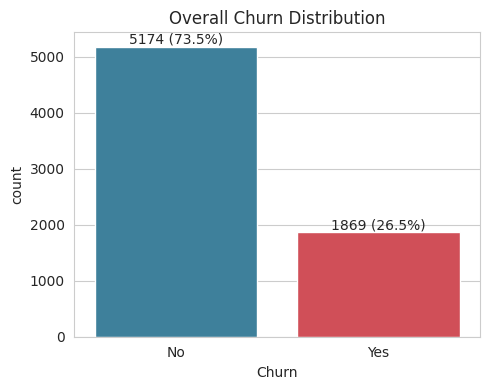

In [7]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100
print(churn_counts)
print(churn_pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='Churn', data=df, hue='Churn', palette=['#2E86AB', '#E63946'], legend=False, ax=ax)
ax.set_title('Overall Churn Distribution')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.tight_layout()
plt.show()


**Insight:** ~26.5% of customers churned vs ~73.5% retained — a **moderately imbalanced** target. Any churn-rate comparison below should be read as "percentage point deviation from this 26.5% baseline."


## 5. Numeric Attributes: Distributions vs Churn

In [8]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print(df[num_cols].describe())


            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


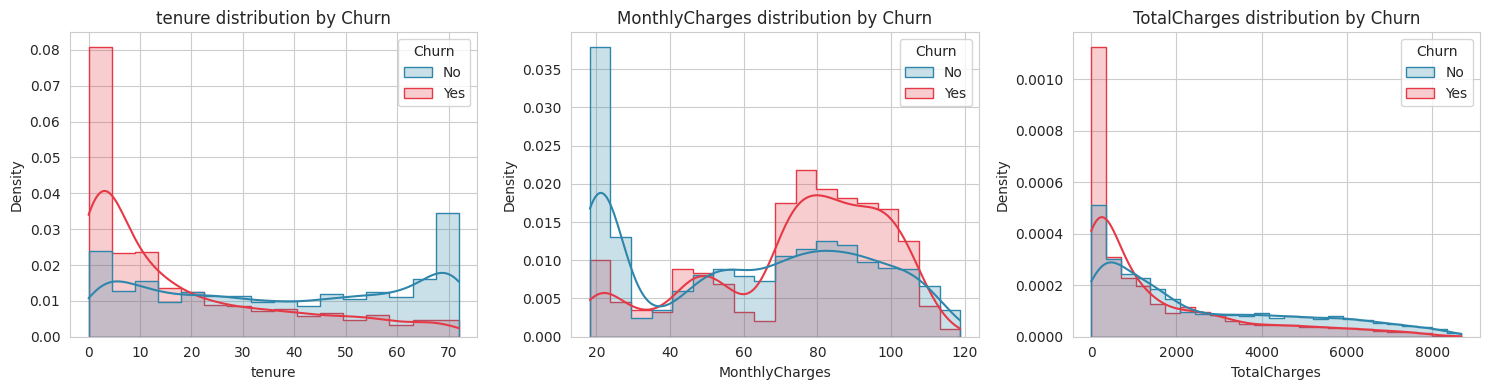

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=ax,
                 palette=['#2E86AB', '#E63946'], element='step',
                 stat='density', common_norm=False)
    ax.set_title(f'{col} distribution by Churn')
plt.tight_layout()
plt.show()


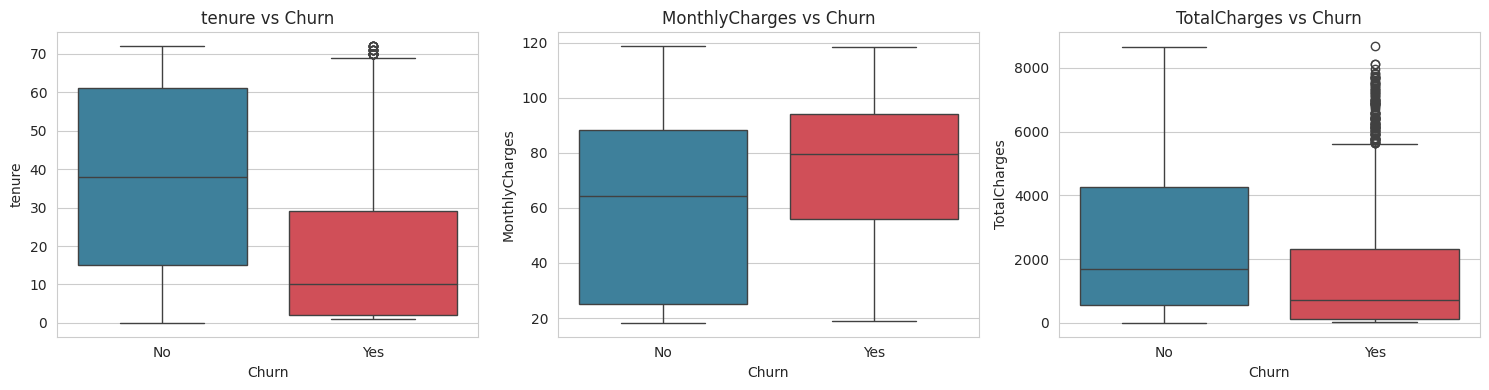

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='Churn', y=col, data=df, hue='Churn', palette=['#2E86AB', '#E63946'], legend=False, ax=ax)
    ax.set_title(f'{col} vs Churn')
plt.tight_layout()
plt.show()


**Insights:**
- **Tenure:** Churned customers are heavily concentrated at **low tenure** (many leave within the first few months). Long-tenured customers rarely churn — loyalty builds over time.
- **MonthlyCharges:** Churned customers skew toward **higher** monthly charges — cost sensitivity appears to be a churn driver.
- **TotalCharges:** Churners have **lower** total charges overall, which is mostly a byproduct of low tenure (less time to accumulate charges), not necessarily lower value.


## 6. Senior Citizens vs Non-Senior Citizens

This is the specific comparison requested in the assignment: *"compare the behavior of senior citizens (SC) and non-SC regarding monthly charges using a Q-Q plot."*


SeniorCitizenLabel
Non-SC    23.61
SC        41.68
Name: Churn, dtype: float64


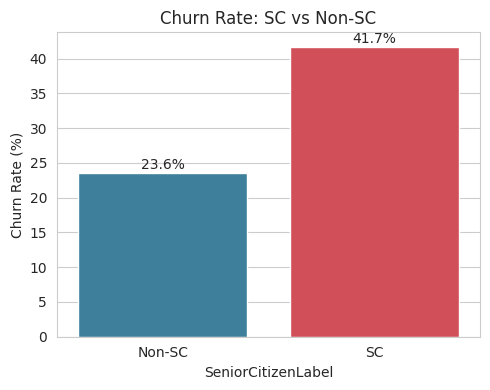

Chi-square test: chi2=159.43, p-value=1.51e-36


In [11]:
sc_churn_rate = df.groupby('SeniorCitizenLabel')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
print(sc_churn_rate.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=sc_churn_rate.index, y=sc_churn_rate.values, hue=sc_churn_rate.index,
            palette=['#2E86AB', '#E63946'], legend=False, ax=ax)
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Churn Rate: SC vs Non-SC')
for i, v in enumerate(sc_churn_rate.values):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

# Statistical test of association
ct = pd.crosstab(df['SeniorCitizen'], df['Churn'])
chi2, p, dof, exp = chi2_contingency(ct)
print(f"Chi-square test: chi2={chi2:.2f}, p-value={p:.2e}")


**Insight:** Senior citizens churn at **41.7%**, almost double the **23.6%** rate for non-seniors, and this association is highly statistically significant (p ≪ 0.001). Senior citizens are clearly a **high-risk segment**.


### Q-Q Plot: MonthlyCharges, SC vs Non-SC

A Q-Q (quantile-quantile) plot compares the quantiles of two distributions. If points fall on the 45° reference line, the distributions are shaped the same (possibly shifted). We build three views:
1. SC MonthlyCharges vs a theoretical Normal distribution.
2. Non-SC MonthlyCharges vs a theoretical Normal distribution.
3. A direct 2-sample Q-Q plot: SC quantiles vs Non-SC quantiles.


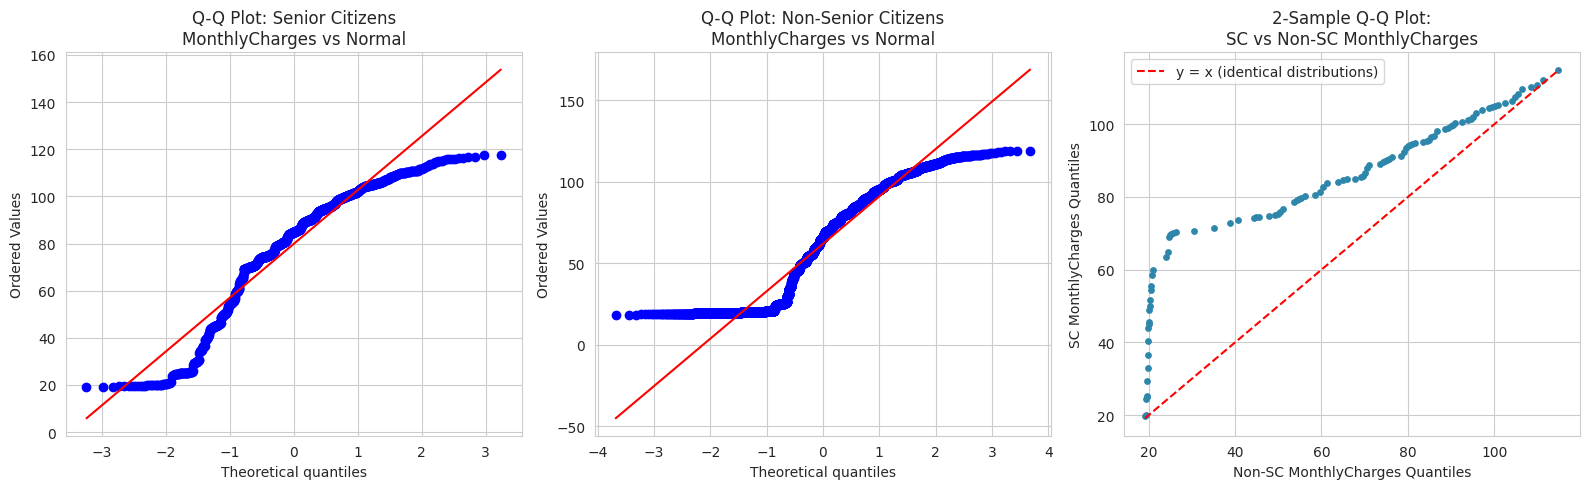

In [12]:
sc_charges = df[df['SeniorCitizen'] == 1]['MonthlyCharges']
nonsc_charges = df[df['SeniorCitizen'] == 0]['MonthlyCharges']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

stats.probplot(sc_charges, dist="norm", plot=axes[0])
axes[0].set_title('Q-Q Plot: Senior Citizens\nMonthlyCharges vs Normal')

stats.probplot(nonsc_charges, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot: Non-Senior Citizens\nMonthlyCharges vs Normal')

q_levels = np.linspace(0.01, 0.99, 99)
sc_q = np.quantile(sc_charges, q_levels)
nonsc_q = np.quantile(nonsc_charges, q_levels)
axes[2].scatter(nonsc_q, sc_q, s=15, color='#2E86AB')
lims = [min(nonsc_q.min(), sc_q.min()), max(nonsc_q.max(), sc_q.max())]
axes[2].plot(lims, lims, 'r--', label='y = x (identical distributions)')
axes[2].set_xlabel('Non-SC MonthlyCharges Quantiles')
axes[2].set_ylabel('SC MonthlyCharges Quantiles')
axes[2].set_title('2-Sample Q-Q Plot:\nSC vs Non-SC MonthlyCharges')
axes[2].legend()

plt.tight_layout()
plt.show()


In [13]:
ks_stat, ks_p = stats.ks_2samp(sc_charges, nonsc_charges)
print(f"KS test: stat={ks_stat:.4f}, p-value={ks_p:.2e}")
print("SC   MonthlyCharges -> mean: {:.2f}, median: {:.2f}".format(sc_charges.mean(), sc_charges.median()))
print("NonSC MonthlyCharges -> mean: {:.2f}, median: {:.2f}".format(nonsc_charges.mean(), nonsc_charges.median()))


KS test: stat=0.3003, p-value=8.01e-77
SC   MonthlyCharges -> mean: 79.82, median: 84.85
NonSC MonthlyCharges -> mean: 61.85, median: 65.80


**Insights from the Q-Q plots:**
- **Individually vs Normal (plots 1 & 2):** Both SC and non-SC MonthlyCharges deviate from a straight line at the tails (S-shaped curve), meaning **neither group's charges are normally distributed** — there's clustering at low values (customers with only phone service, ~\$19–20) and a ceiling near \$115–120 (customers with all premium add-ons).
- **2-sample Q-Q plot (plot 3):** Every quantile point lies **above** the y = x reference line. This means at *every* percentile, senior citizens pay more than non-seniors — it's not just a difference in the mean but a **consistent upward shift across the whole distribution**.
- This is confirmed by the Kolmogorov–Smirnov test (p ≪ 0.001): the two distributions are statistically different, not from the same underlying distribution.
- **Combined with the churn-rate finding above:** Senior citizens tend to have **higher monthly bills** *and* **churn nearly twice as often** — high charges are a plausible contributing factor to their elevated churn risk, alongside other factors (e.g., service preferences) explored below.


## 7. Other Categorical Attributes vs Churn

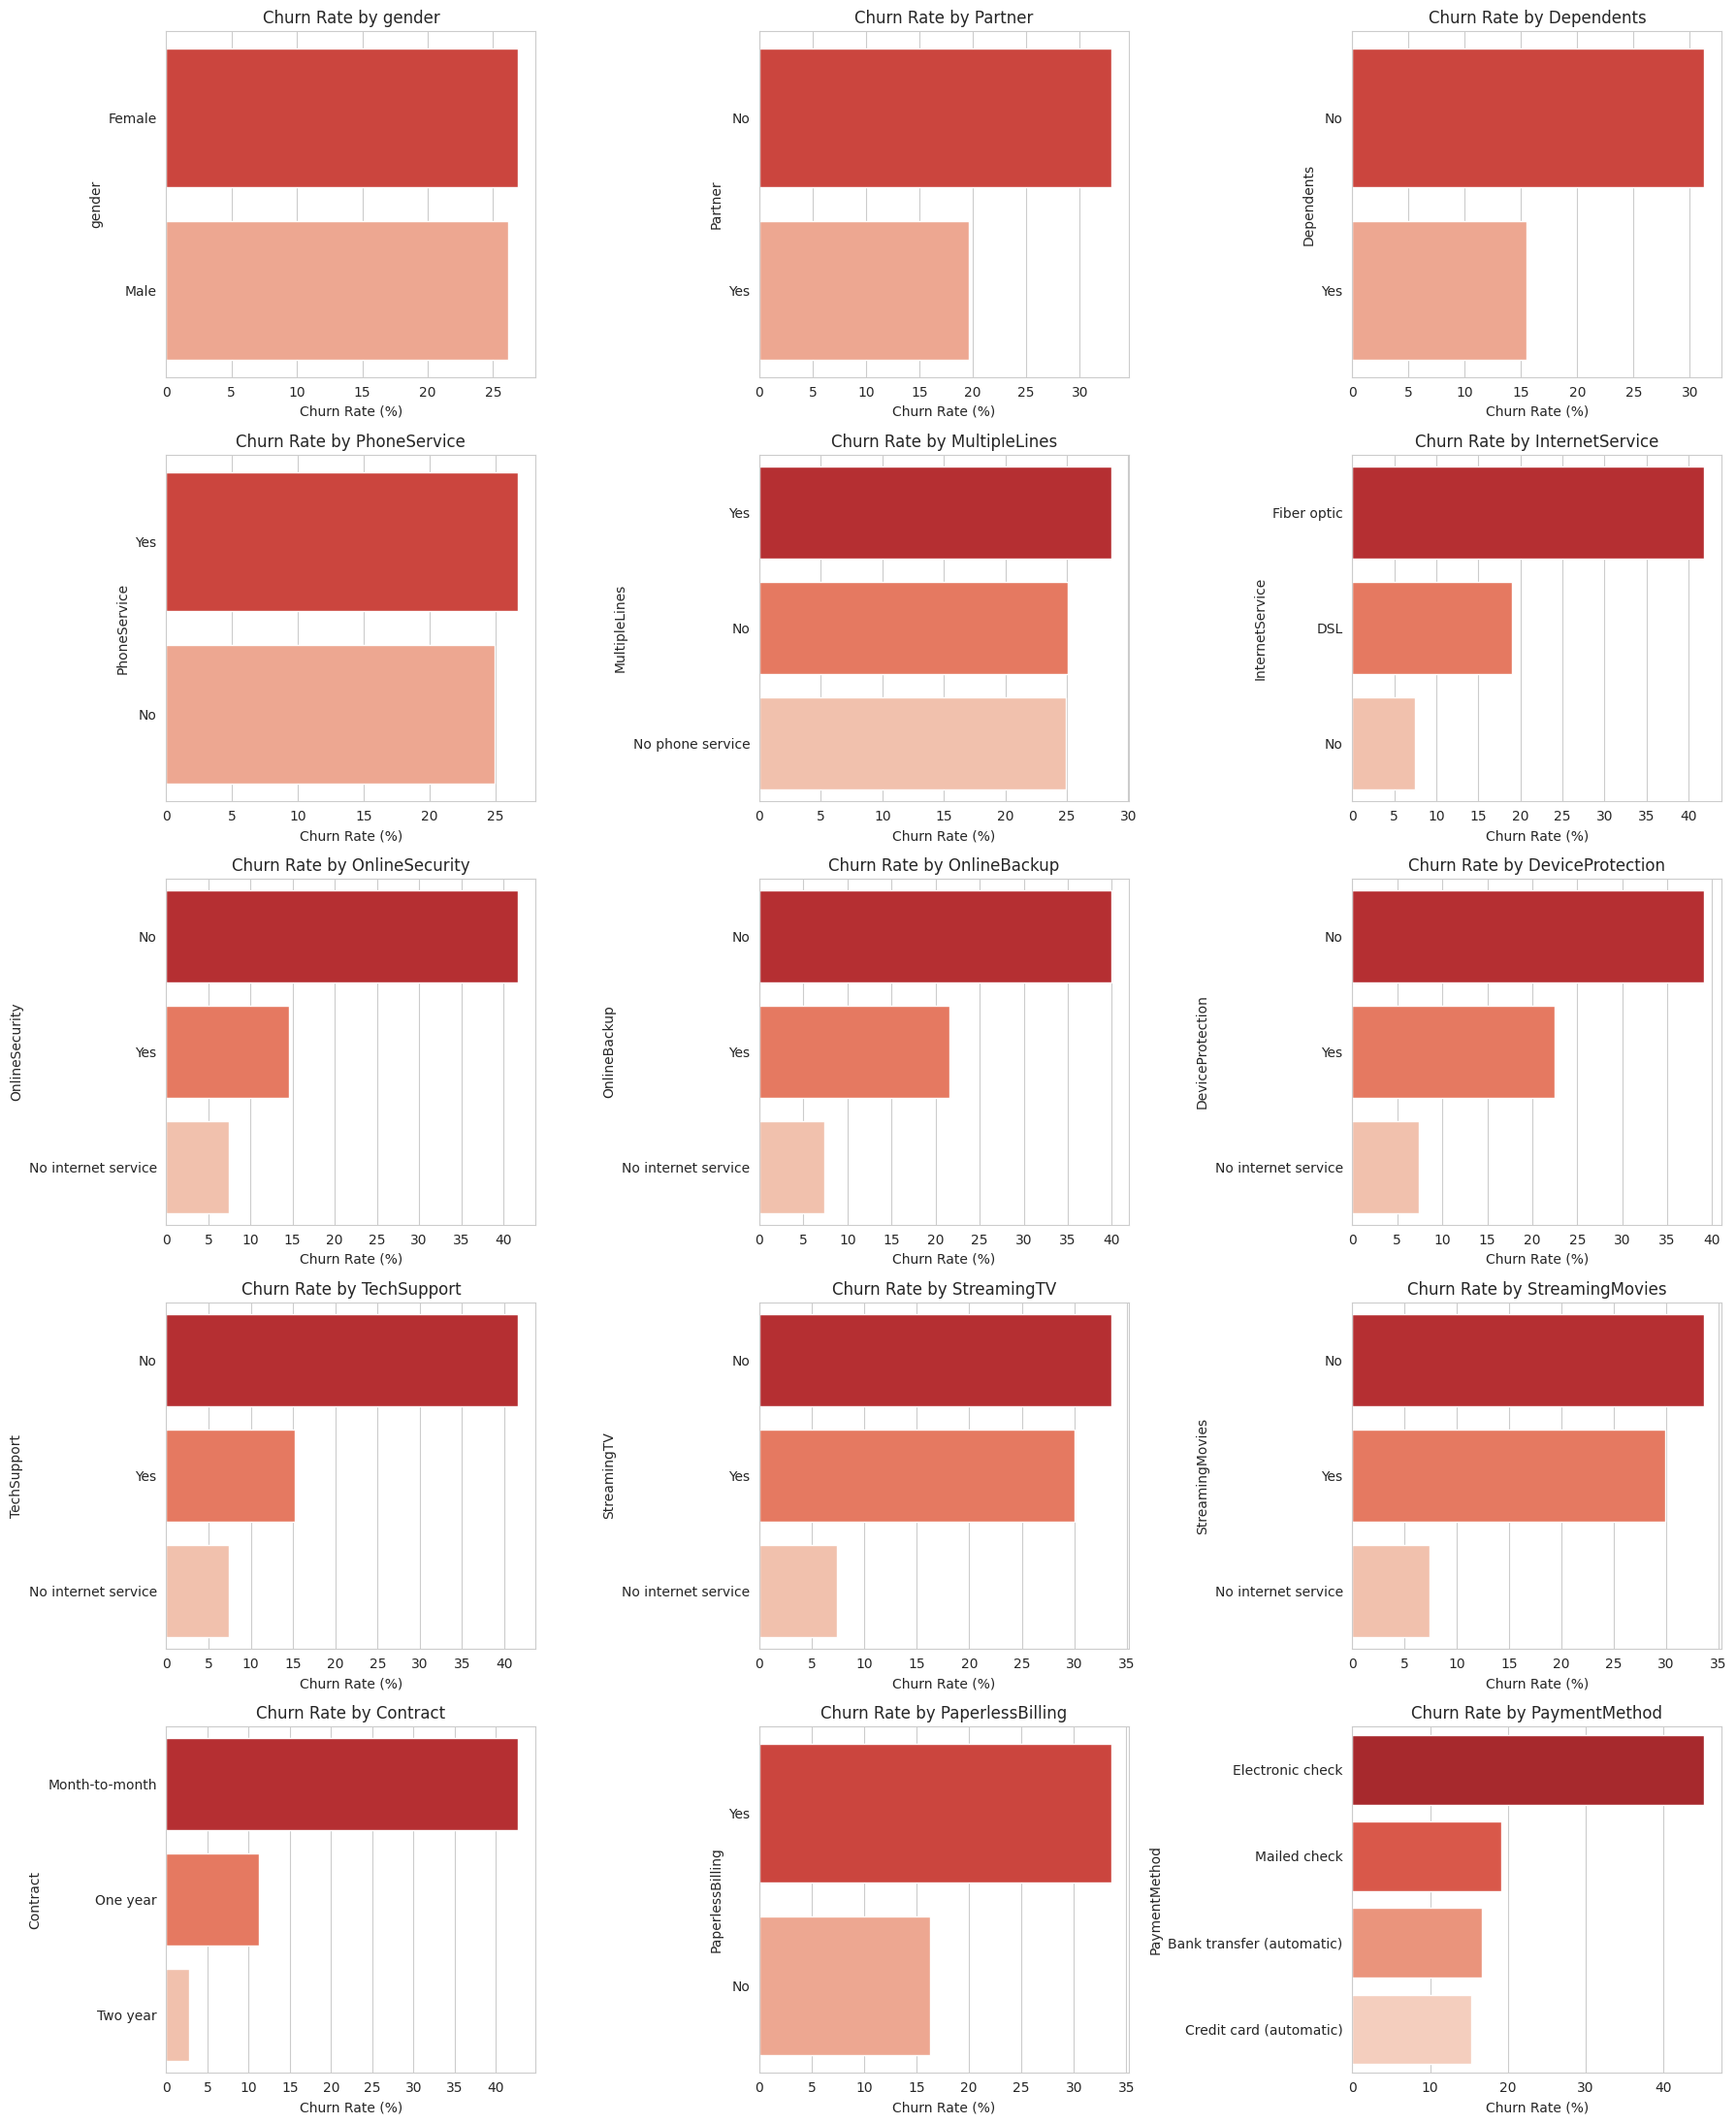

In [14]:
cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod']

fig, axes = plt.subplots(5, 3, figsize=(18, 22))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    rate = df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, hue=rate.index, palette='Reds_r', legend=False, ax=axes[i])
    axes[i].set_title(f'Churn Rate by {col}')
    axes[i].set_xlabel('Churn Rate (%)')
for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


**Key insights:**
- **Contract type** is the strongest categorical driver: **Month-to-month** contracts churn far more than **One-year** or **Two-year** contracts — longer commitments reduce churn sharply.
- **Internet service = Fiber optic** customers churn more than DSL or no-internet customers, despite (or because of) it being the premium option — likely a price/reliability trade-off.
- Customers **without** `OnlineSecurity`, `TechSupport`, `OnlineBackup`, or `DeviceProtection` churn considerably more than those with these add-ons — these services seem to build "stickiness."
- `PaperlessBilling = Yes` and `PaymentMethod = Electronic check` both associate with higher churn.
- `gender` shows almost **no difference** in churn — not a useful predictor.
- Customers with a `Partner` or `Dependents` churn less — suggests household stability correlates with retention.


## 8. Tenure & Contract Interaction

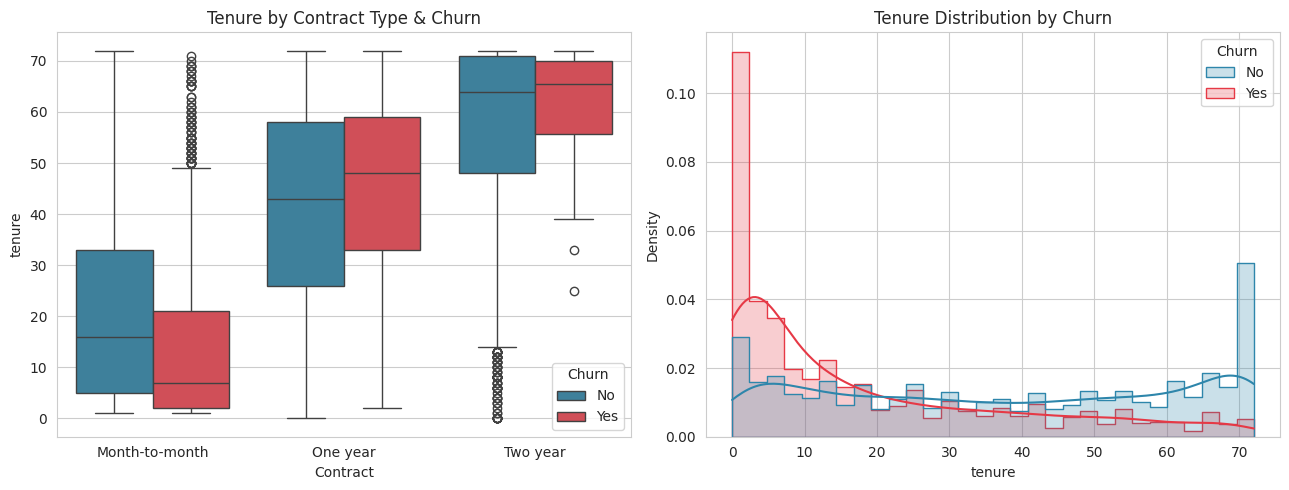

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(x='Contract', y='tenure', hue='Churn', data=df, ax=axes[0], palette=['#2E86AB', '#E63946'])
axes[0].set_title('Tenure by Contract Type & Churn')

sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True, ax=axes[1],
             palette=['#2E86AB', '#E63946'], element='step', stat='density', common_norm=False)
axes[1].set_title('Tenure Distribution by Churn')
plt.tight_layout()
plt.show()


**Insight:** Churn is concentrated in the **first ~10 months** of tenure, regardless of contract type, but month-to-month customers are far more likely to leave at any given tenure level than contract customers — early-tenure, no-commitment customers are the highest-risk group.


## 9. Correlation Among Numeric Features

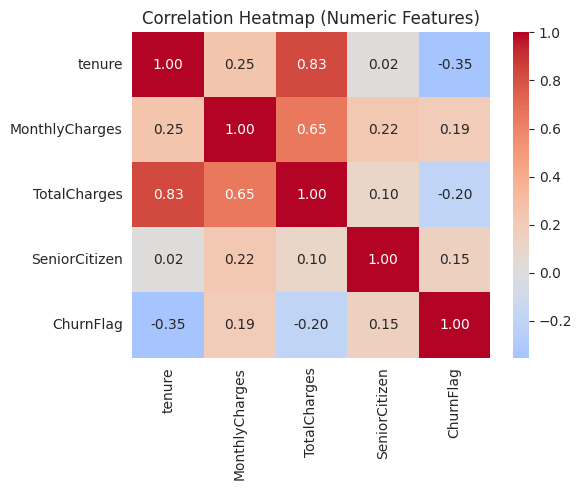

In [16]:
df_corr = df.copy()
df_corr['ChurnFlag'] = (df_corr['Churn'] == 'Yes').astype(int)
corr = df_corr[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', ax=ax)
ax.set_title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.show()


**Insight:** `tenure` and `TotalCharges` are strongly positively correlated (expected — longer tenure accumulates more billing). `ChurnFlag` correlates negatively with `tenure` (-0.35 range) and positively with `MonthlyCharges`, reinforcing the earlier findings: **short tenure + high monthly charges = elevated churn risk**.


## 10. Overall Summary — Who Is More Likely to Churn?

Based on this EDA, the customer profile most likely to churn is:

1. **Senior citizens** — churn ~42% vs ~24% for non-seniors (statistically significant, χ² p ≪ 0.001), and they pay more at every quantile of MonthlyCharges (Q-Q plot, KS test p ≪ 0.001).
2. **Low-tenure customers** — most churn happens in the first ~10 months.
3. **Month-to-month contract holders** — vs one/two-year contracts.
4. **Fiber optic internet subscribers** without add-on services (OnlineSecurity, TechSupport, OnlineBackup, DeviceProtection).
5. **High MonthlyCharges** customers in general.
6. **Electronic check** payers and **paperless billing** users.
7. Customers **without a partner or dependents** (less household stability).

`gender` shows negligible impact and is not a useful churn signal.

**Business implication:** Retention efforts should prioritize senior citizens and new (low-tenure) month-to-month customers, potentially by encouraging longer contracts or bundling protective/support add-ons which are associated with much lower churn.
